# Telecom Customer Churn Prediction — 2026 Technical Review

**Author of this review:** Elena Boiko

**Project context:** Collaborative machine learning course project, University of West Florida, Fall 2024 (Kaggle competition held within the class).
**My contribution:** Exploratory data analysis, XGBoost modeling and tuning, model comparison, and participation in selecting the final XGBoost model.
The original notebook is not published; its historical results are summarized in the README. The 2026 technical review and its corrections are my own work.

## Purpose
In 2026 I re-ran the team project and reviewed the code. This notebook repeats the original experiment with **the same data, the same 70/30 stratified split (`random_state=17`), the same preprocessing and the same models**. Only the errors found in the review are fixed. Every fix is marked in the code with `# 2026 FIX`.

## What was fixed
1. **Hyperparameter tuning.** The shared helper `tune_model()` ran `RandomizedSearchCV` but then re-fit and returned the *original, untuned* model. All models except XGBoost were therefore evaluated with default parameters. Fixed: the helper now returns `best_estimator_`.
2. **Threshold selection for F1 (XGBoost).** The optimal threshold was chosen on the test set, which inflates the test F1. Fixed: the threshold is chosen with 5-fold cross-validated predictions on the training set only, then applied once to the test set.
3. **Imputation of `total_charges`.** The mean imputer was re-fit on every dataset (including test). Fixed: fit on training data, applied to test.
4. **Metrics table.** The original comparison table was typed in by hand. Fixed: the table is built from the values computed in this run.

SMOTE was imported in the original notebook, but the resampled data were never used for training. This review keeps the original behavior (no resampling) and does not claim SMOTE.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.feature_selection import SelectFromModel
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, precision_recall_curve
import xgboost as xgb

RANDOM_STATE = 17

# Path to train.csv. On Kaggle: upload train.csv as a dataset and change the path.
DATA_PATH = "train.csv"

import os
IMG_DIR, RES_DIR = "images", "results"      # on Kaggle these appear in /kaggle/working
os.makedirs(IMG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

## 2. Load data

In [2]:
data_raw_input = pd.read_csv(DATA_PATH)
print(data_raw_input.shape)
print(data_raw_input["label"].value_counts())

(5634, 21)
label
0    4113
1    1521
Name: count, dtype: int64


## 3. Exploratory Data Analysis
My part of the original project: visual analysis of the target and the main features.

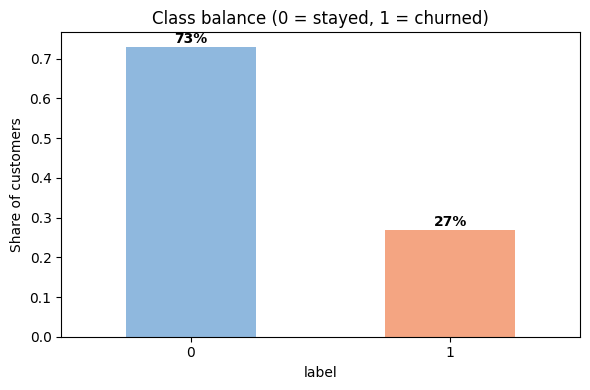

In [3]:
import seaborn as sns
churn_share = data_raw_input["label"].value_counts(normalize=True).sort_index()
ax = churn_share.plot(kind="bar", color=["#8fb8de", "#f4a582"], figsize=(6, 4), rot=0)
for i, v in enumerate(churn_share):
    ax.text(i, v + 0.01, f"{v:.0%}", ha="center", fontweight="bold")
plt.title("Class balance (0 = stayed, 1 = churned)"); plt.ylabel("Share of customers")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/churn_distribution.png", dpi=120); plt.show()

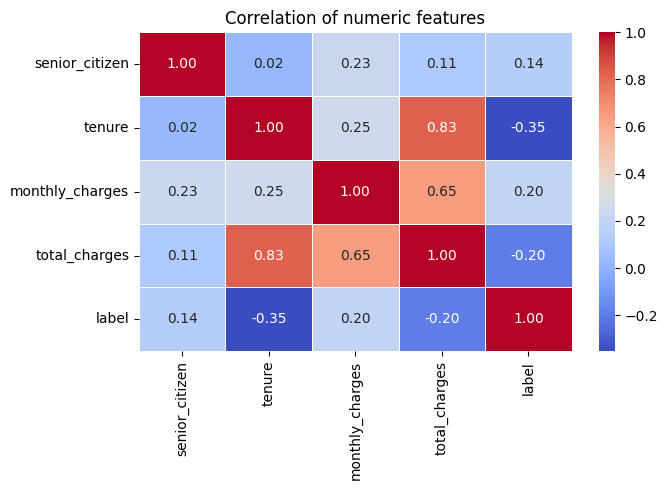

In [4]:
eda = data_raw_input.copy()
eda["total_charges"] = pd.to_numeric(eda["total_charges"].replace(" ", np.nan))
num_cols = ["senior_citizen", "tenure", "monthly_charges", "total_charges", "label"]
plt.figure(figsize=(7, 5))
sns.heatmap(eda[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation of numeric features"); plt.tight_layout(); plt.show()

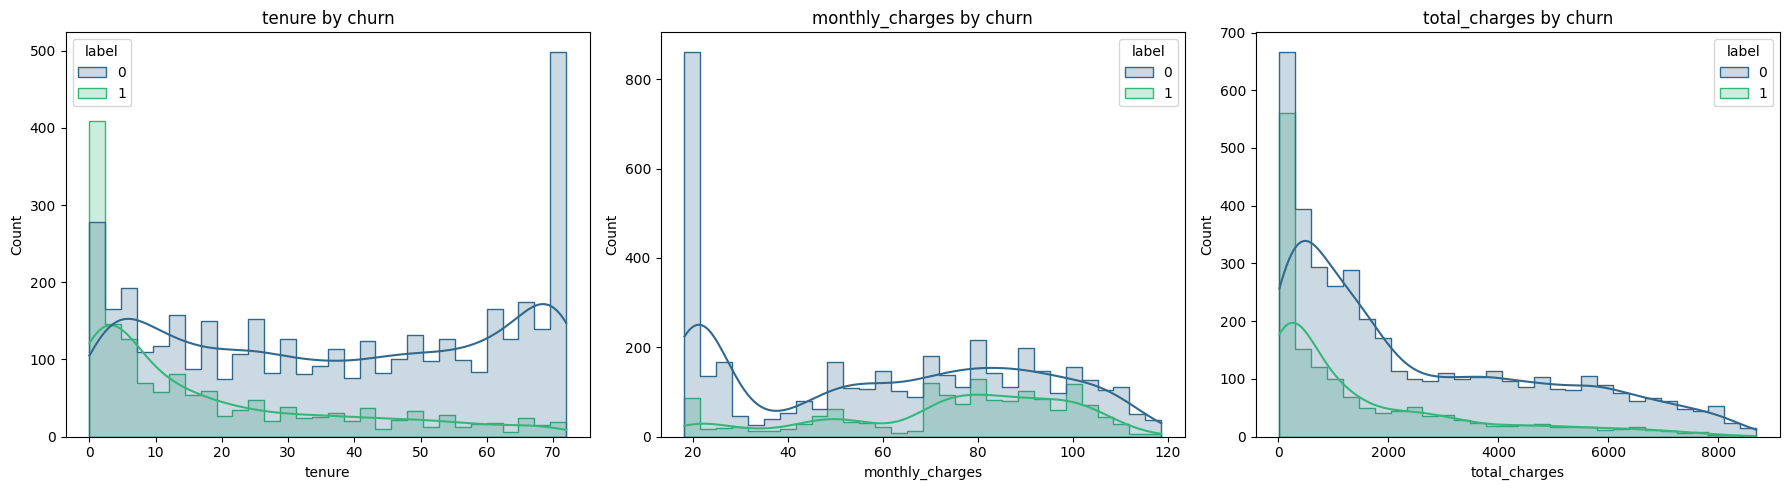

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feature in zip(axes, ["tenure", "monthly_charges", "total_charges"]):
    sns.histplot(data=eda, x=feature, hue="label", kde=True, bins=30, element="step", palette="viridis", ax=ax)
    ax.set_title(f"{feature} by churn")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/numeric_features_by_churn.png", dpi=120); plt.show()

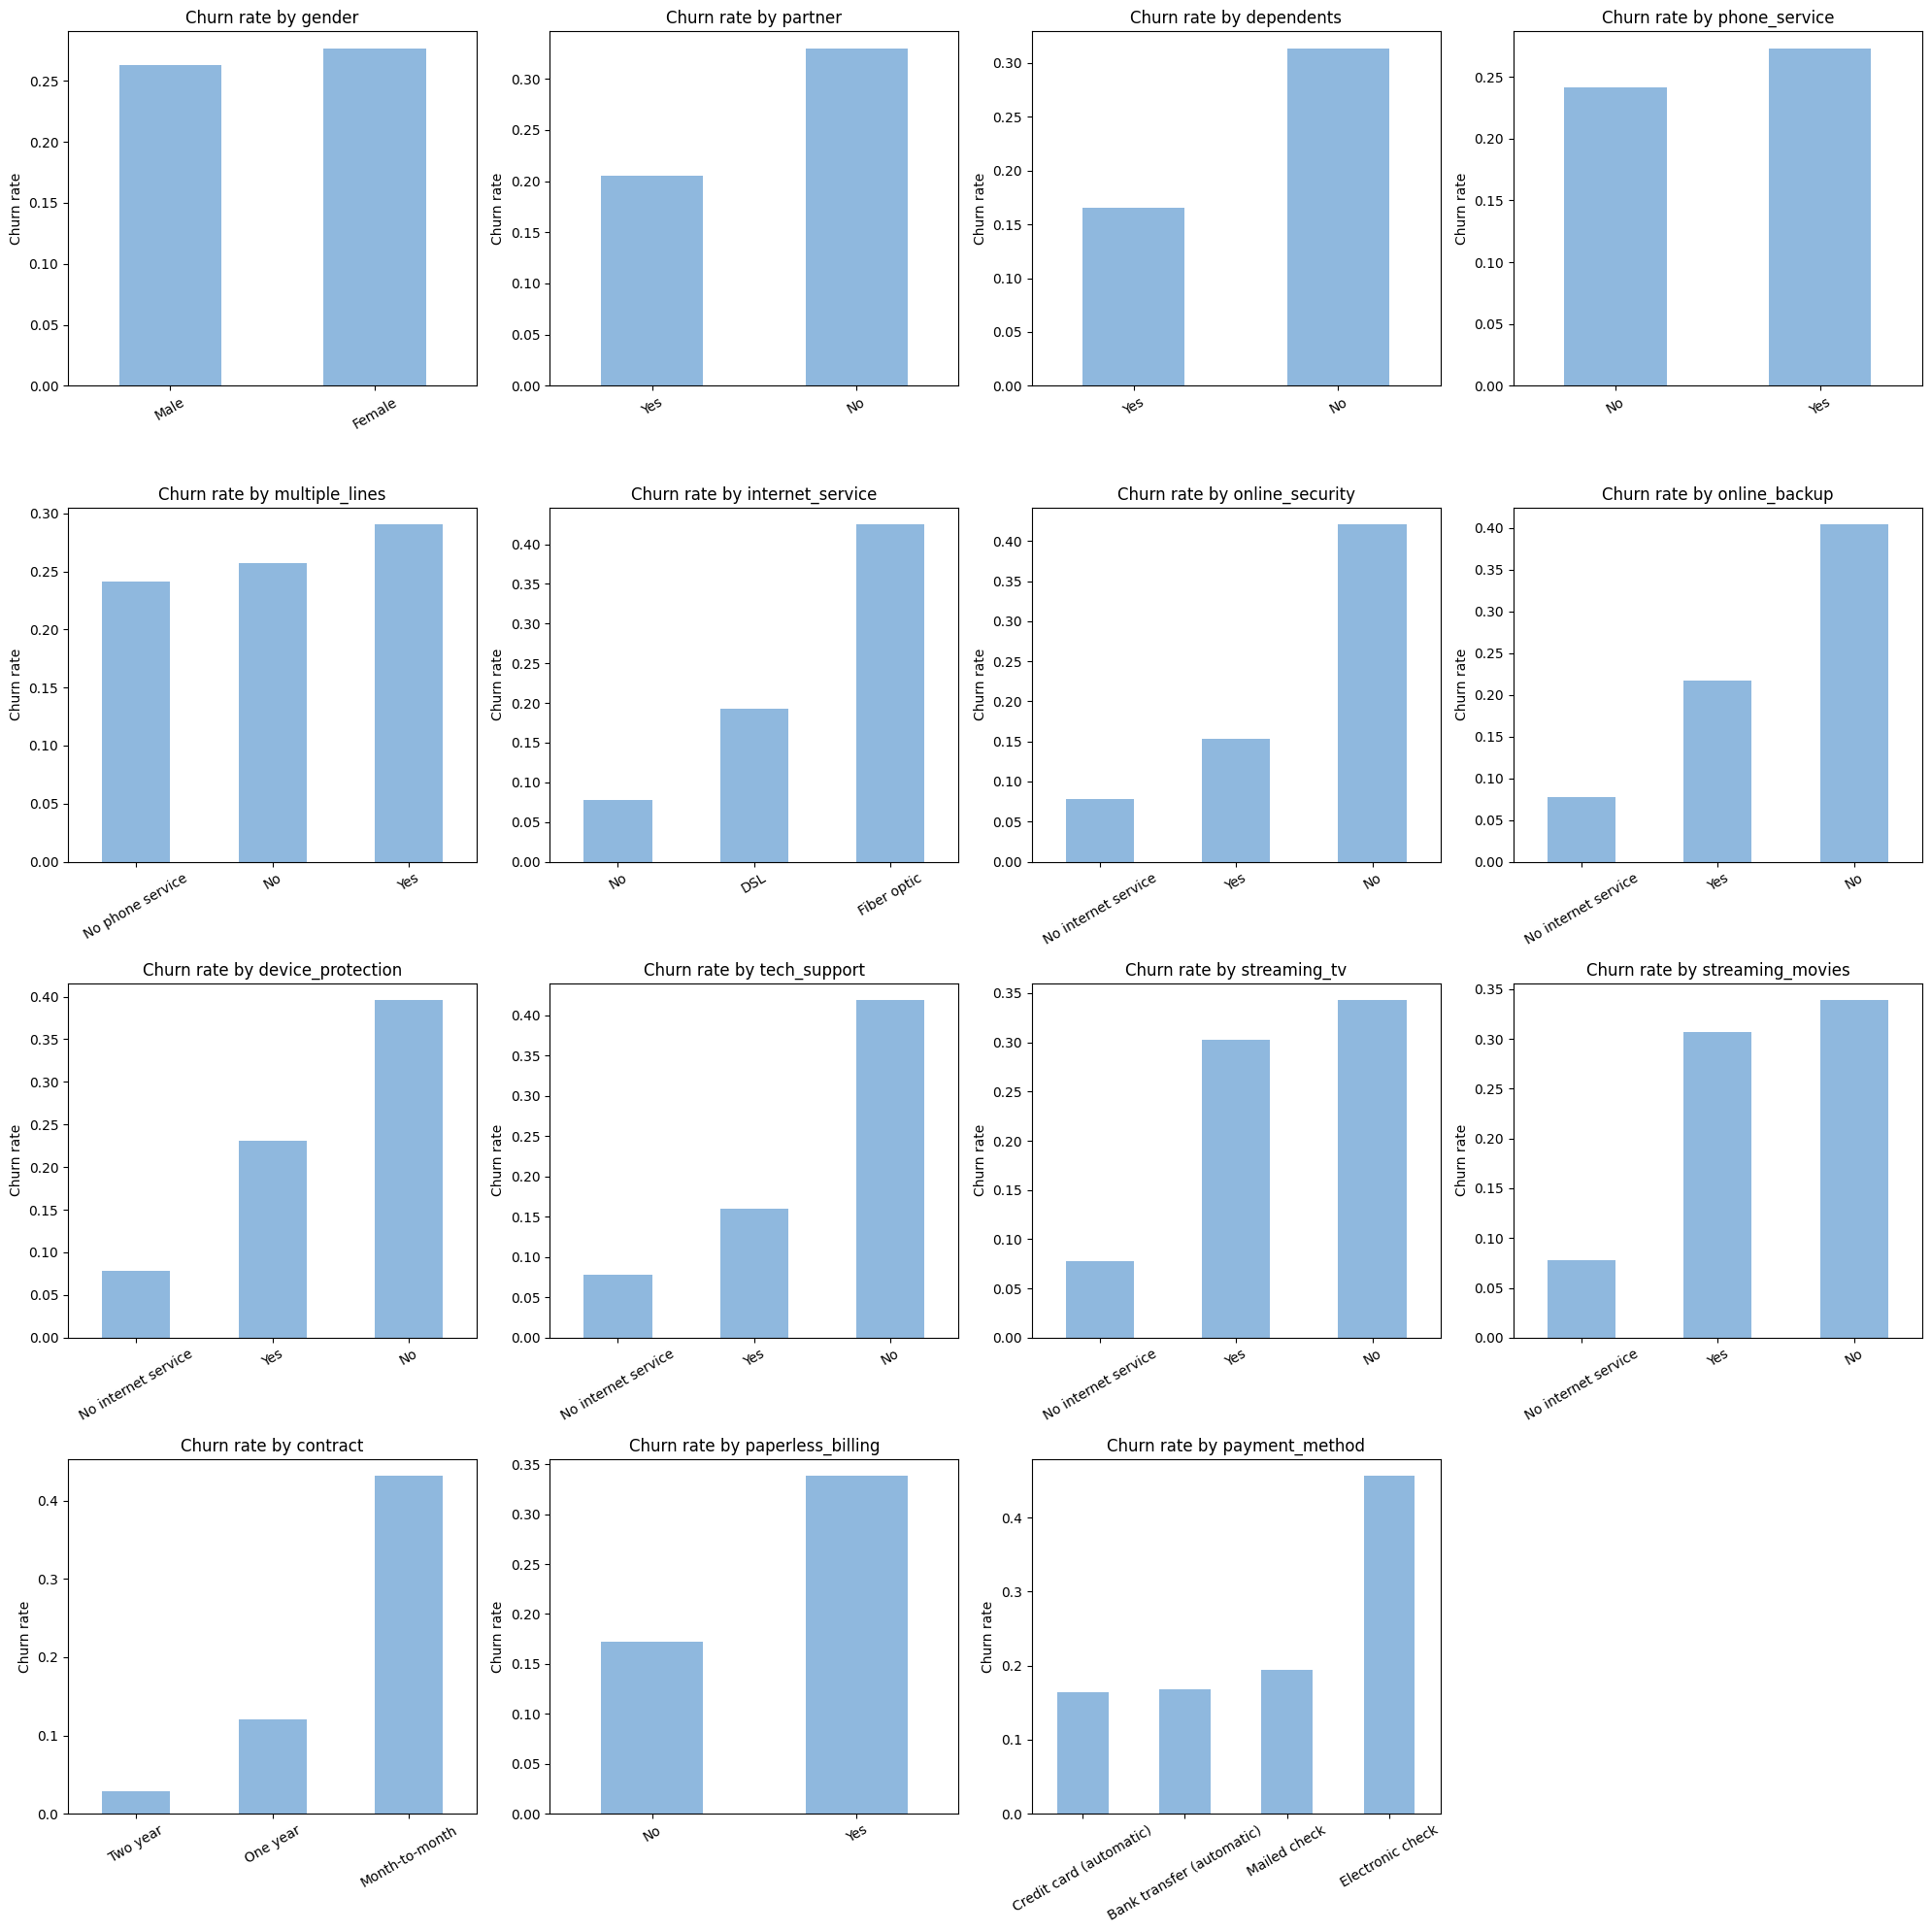

In [6]:
cat_features = [c for c in data_raw_input.select_dtypes(include="object").columns if c != "total_charges"]
n_rows = int(np.ceil(len(cat_features) / 4))
fig, axes = plt.subplots(n_rows, 4, figsize=(20, 5 * n_rows)); axes = axes.flatten()
for ax, col in zip(axes, cat_features):
    rate = data_raw_input.groupby(col)["label"].mean().sort_values()
    rate.plot(kind="bar", ax=ax, color="#8fb8de", rot=30)
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate"); ax.set_xlabel("")
for ax in axes[len(cat_features):]:
    fig.delaxes(ax)
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/churn_rate_by_category.png", dpi=120); plt.show()

## 4. Preprocessing
Same steps as the original pipeline: `total_charges` blanks → NaN → numeric → mean imputation; `StandardScaler` for numeric columns; `LabelEncoder` for text columns.

In [8]:
class MultiPrep:
    def __init__(self):
        self.feature_encoders = {}

    def fit_text_encoders(self, df):
        for col in df.select_dtypes(exclude="number").columns:
            self.feature_encoders[col] = LabelEncoder().fit(df[col])

    def fit_scaler(self, df):
        numeric_columns = df.select_dtypes(include="number").columns
        self.feature_encoders["numerics"] = StandardScaler().fit(df[numeric_columns])

    def transform_scale_all(self, df):
        numeric_columns = df.select_dtypes(include="number").columns
        df[numeric_columns] = self.feature_encoders["numerics"].transform(df[numeric_columns])
        return df

    def transform_encode_all(self, df):
        for col in df.select_dtypes(exclude="number").columns:
            df[col] = self.feature_encoders[col].transform(df[col])
        return df


def split_x_y(data_raw):
    return data_raw.drop(columns=["label", "id"]), data_raw["label"]


multiprep = MultiPrep()
imputer = SimpleImputer(strategy="mean")


def transform_features(X, transform_only):
    X = X.copy()
    X["total_charges"] = pd.to_numeric(X["total_charges"].replace(" ", np.nan))
    if not transform_only:
        imputer.fit(X[["total_charges"]])                     # 2026 FIX: fit imputer on training data only
    X["total_charges"] = imputer.transform(X[["total_charges"]]).ravel()

    if not transform_only:
        multiprep.fit_text_encoders(X)
        multiprep.fit_scaler(X)
    X = multiprep.transform_scale_all(X)
    X = multiprep.transform_encode_all(X)
    return X

## 5. Train/test split (same as original)

In [9]:
X_without_label, y_values = split_x_y(data_raw_input)
X_train, X_test, y_train, y_test = train_test_split(
    X_without_label, y_values, test_size=0.3, stratify=y_values, random_state=RANDOM_STATE)

X_train = transform_features(X_train, transform_only=False)
X_test = transform_features(X_test, transform_only=True)
print(X_train.shape, X_test.shape)

(3943, 19) (1691, 19)


## 6. Tuning helper and results collector

In [10]:
def tune_model(model, param_grid, X, y, scoring="roc_auc"):
    rscv = RandomizedSearchCV(model, param_distributions=param_grid, scoring=scoring,
                              cv=5, random_state=RANDOM_STATE, refit=True)
    rscv.fit(X, y)
    print("CV ROC-AUC:", round(rscv.best_score_, 4))
    print("Best params:", rscv.best_params_)
    return rscv.best_estimator_                                # 2026 FIX: original returned the untuned model


results = {}      # 2026 FIX: metrics table is built from computed values, not typed by hand
probas = {}

def evaluate(name, model, Xte=None):
    Xte = X_test if Xte is None else Xte
    proba = model.predict_proba(Xte)[:, 1]
    pred = model.predict(Xte)
    results[name] = {"Accuracy": accuracy_score(y_test, pred),
                     "F1 (thr 0.5)": f1_score(y_test, pred),
                     "ROC-AUC": roc_auc_score(y_test, proba)}
    probas[name] = proba
    print(name, {k: round(v, 4) for k, v in results[name].items()})

## 7. Models (same models and parameter grids as original)

### 7.1 Logistic Regression — baseline

In [11]:
lr_grid = {"solver": ["liblinear", "newton-cg", "saga", "lbfgs"],
           "C": [0.001, 0.01, 1.0, 3.0, 5.0, 7.0, 10.0, 12.0]}
lr_baseline = tune_model(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000), lr_grid, X_train, y_train)
evaluate("Logistic Regression (Baseline)", lr_baseline)

CV ROC-AUC: 0.8415
Best params: {'solver': 'liblinear', 'C': 10.0}
Logistic Regression (Baseline) {'Accuracy': 0.8001, 'F1 (thr 0.5)': 0.6033, 'ROC-AUC': np.float64(0.8384)}


### 7.2 Logistic Regression — PCA (6 components)

In [16]:
pca = PCA(n_components=6)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
lr_pca = tune_model(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000), lr_grid, X_train_pca, y_train)
evaluate("Logistic Regression (PCA)", lr_pca, X_test_pca)

CV ROC-AUC: 0.8327
Best params: {'solver': 'newton-cg', 'C': 0.01}
Logistic Regression (PCA) {'Accuracy': 0.7853, 'F1 (thr 0.5)': 0.5546, 'ROC-AUC': np.float64(0.8221)}


### 7.3 Logistic Regression — feature selection

In [17]:
sfm = SelectFromModel(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000).fit(X_train, y_train),
                      prefit=True, threshold=0.05)
X_train_sel = sfm.transform(X_train)
X_test_sel = sfm.transform(X_test)
lr_sel = tune_model(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000), lr_grid, X_train_sel, y_train)
evaluate("Logistic Regression (Feature Selection)", lr_sel, X_test_sel)

CV ROC-AUC: 0.843
Best params: {'solver': 'saga', 'C': 10.0}
Logistic Regression (Feature Selection) {'Accuracy': 0.7972, 'F1 (thr 0.5)': 0.596, 'ROC-AUC': np.float64(0.838)}


### 7.4 Decision Tree

In [18]:
dt_grid = {"max_depth": [80, 60, 40, 20, 10, 5], "criterion": ["gini", "entropy", "log_loss"]}
dt = tune_model(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid, X_train, y_train)
evaluate("Decision Tree", dt)

CV ROC-AUC: 0.8212
Best params: {'max_depth': 5, 'criterion': 'entropy'}
Decision Tree {'Accuracy': 0.7824, 'F1 (thr 0.5)': 0.5067, 'ROC-AUC': np.float64(0.8117)}


### 7.5 Random Forest
Note: the original grid uses `max_features` values (40–100) larger than the number of features (19). With 19 features, scikit-learn effectively considers all available features at each split, so this parameter does not change the model. The grid is kept as in the original.

In [19]:
rf_grid = {"criterion": ["gini", "entropy"], "n_estimators": [50, 100, 150],
           "max_features": [40, 60, 80, 100], "max_depth": [80, 50, 20, 10, 5]}
rf = tune_model(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_grid, X_train, y_train)
evaluate("Random Forest", rf)

CV ROC-AUC: 0.8403
Best params: {'n_estimators': 100, 'max_features': 40, 'max_depth': 5, 'criterion': 'entropy'}
Random Forest {'Accuracy': 0.7895, 'F1 (thr 0.5)': 0.5365, 'ROC-AUC': np.float64(0.8274)}


### 7.6 SVM (may take a few minutes)

In [20]:
param_range = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
svm_grid = [{"C": param_range, "kernel": ["linear"]},
            {"C": param_range, "gamma": param_range, "kernel": ["rbf"]}]
svm = tune_model(SVC(probability=True, random_state=RANDOM_STATE), svm_grid, X_train, y_train)
evaluate("SVM", svm)

CV ROC-AUC: 0.8323
Best params: {'kernel': 'rbf', 'gamma': 0.01, 'C': 0.1}
SVM {'Accuracy': 0.7664, 'F1 (thr 0.5)': 0.3639, 'ROC-AUC': np.float64(0.8197)}


### 7.7 KNN

In [21]:
knn = tune_model(KNeighborsClassifier(), {"n_neighbors": [4, 6, 8, 10, 12]}, X_train, y_train)
evaluate("KNN", knn)

CV ROC-AUC: 0.8038
Best params: {'n_neighbors': 12}
KNN {'Accuracy': 0.7646, 'F1 (thr 0.5)': 0.534, 'ROC-AUC': np.float64(0.7915)}


### 7.8 Voting Classifier (same fixed parameters as original)

In [22]:
voting_clf = VotingClassifier(estimators=[
    ("lr", LogisticRegression(solver="liblinear", C=10.0, random_state=RANDOM_STATE)),
    ("dt", DecisionTreeClassifier(max_depth=5, criterion="entropy", random_state=RANDOM_STATE)),
    ("svm", SVC(probability=True, kernel="rbf", gamma=0.01, C=0.1, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier(n_neighbors=4))], voting="soft")
voting_clf.fit(X_train, y_train)
evaluate("Voting Classifier", voting_clf)

Voting Classifier {'Accuracy': 0.7954, 'F1 (thr 0.5)': 0.59, 'ROC-AUC': np.float64(0.8285)}


### 7.9 Bagging Classifier (same as original)

In [23]:
bag = BaggingClassifier(estimator=DecisionTreeClassifier(criterion="entropy", max_depth=None, random_state=RANDOM_STATE),
                        n_estimators=500, max_samples=1.0, max_features=0.4, bootstrap=True,
                        bootstrap_features=False, n_jobs=-1, random_state=RANDOM_STATE)
bag.fit(X_train, y_train)
print("Train accuracy:", round(accuracy_score(y_train, bag.predict(X_train)), 4))
evaluate("Bagging Classifier", bag)

Train accuracy: 0.9896
Bagging Classifier {'Accuracy': 0.7901, 'F1 (thr 0.5)': 0.5298, 'ROC-AUC': np.float64(0.8227)}


### 7.10 XGBoost — initial model (my part of the original project)

In [24]:
xgb_initial = xgb.XGBClassifier(n_estimators=500, learning_rate=0.01, max_depth=4, random_state=RANDOM_STATE)
xgb_initial.fit(X_train, y_train)
print("Train accuracy:", round(accuracy_score(y_train, xgb_initial.predict(X_train)), 4))
evaluate("XGBoost (Initial)", xgb_initial)

Train accuracy: 0.8268
XGBoost (Initial) {'Accuracy': 0.7895, 'F1 (thr 0.5)': 0.5711, 'ROC-AUC': np.float64(0.8374)}


### 7.11 XGBoost — tuned (my part of the original project; tuning was already correct)

In [25]:
xgb_grid = {"n_estimators": [300, 500, 700], "learning_rate": [0.01, 0.02, 0.05], "max_depth": [4, 5, 6],
            "min_child_weight": [1, 2], "subsample": [0.8, 0.9, 1.0], "colsample_bytree": [0.8, 0.9, 1.0],
            "gamma": [0, 0.1, 0.2], "reg_alpha": [0.0, 0.1], "reg_lambda": [0.5, 1.0, 1.5]}
random_search = RandomizedSearchCV(xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"),
                                   param_distributions=xgb_grid, n_iter=50, scoring="roc_auc",
                                   cv=5, random_state=42, n_jobs=-1)
random_search.fit(X_train, y_train)
best_xgb = random_search.best_estimator_
print("Best params:", random_search.best_params_)
evaluate("XGBoost (Tuned)", best_xgb)

Best params: {'subsample': 0.9, 'reg_lambda': 0.5, 'reg_alpha': 0.0, 'n_estimators': 300, 'min_child_weight': 2, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.9}
XGBoost (Tuned) {'Accuracy': 0.7859, 'F1 (thr 0.5)': 0.5464, 'ROC-AUC': np.float64(0.8374)}


### 7.12 XGBoost — threshold for F1 chosen on training data
2026 FIX: the threshold is selected from 5-fold cross-validated predictions on the training set, then applied once to the test set. The test set is not used. Note that the XGBoost hyperparameters were already tuned on the same training set, so these out-of-fold predictions are not fully independent of the tuning step.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(xgb.XGBClassifier(**best_xgb.get_params()), X_train, y_train,
                              cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = thr[f1s.argmax()]
print("Threshold chosen on training CV:", round(best_threshold, 4))

pred_thr = (probas["XGBoost (Tuned)"] >= best_threshold).astype(int)
xgb_f1_thr = f1_score(y_test, pred_thr)
print("Test F1 at this threshold:", round(xgb_f1_thr, 4))

Threshold chosen on training CV: 0.3121
Test F1 at this threshold: 0.6294


**Interpretation:** With the threshold chosen on training data (0.31), test F1 is 0.629, close to the originally reported 0.639. The original threshold was only slightly overfitted to the test set. A lower threshold catches more churners at the cost of more false alarms, which suits retention campaigns where missing a churner costs more than an unnecessary offer.

## 8. Results

In [27]:
metrics_df = pd.DataFrame(results).T.round(4).sort_values("ROC-AUC", ascending=False)
metrics_df.loc["XGBoost (Tuned)", "F1 (CV threshold)"] = round(xgb_f1_thr, 4)
metrics_df.to_csv(f"{RES_DIR}/model_evaluation.csv")
metrics_df

,Accuracy,F1 (thr 0.5),ROC-AUC,F1 (CV threshold)
Logistic Regression (Baseline),0.8001,0.6033,0.8384,NaN
Logistic Regression (Feature Selection),0.7972,0.5960,0.8380,NaN
XGBoost (Initial),0.7895,0.5711,0.8374,NaN
XGBoost (Tuned),0.7859,0.5464,0.8374,0.6294
Voting Classifier,0.7954,0.5900,0.8285,NaN
Random Forest,0.7895,0.5365,0.8274,NaN
Bagging Classifier,0.7901,0.5298,0.8227,NaN
Logistic Regression (PCA),0.7853,0.5546,0.8221,NaN
SVM,0.7664,0.3639,0.8197,NaN
Decision Tree,0.7824,0.5067,0.8117,NaN


### 8.1 Original (2024) vs corrected (2026) test ROC-AUC

In [28]:
original_auc = {   # values as reported in the original notebook
    "Logistic Regression (Baseline)": 0.8383, "Logistic Regression (PCA)": 0.8222,
    "Logistic Regression (Feature Selection)": 0.8378, "Decision Tree": 0.6576,
    "Random Forest": 0.8193, "SVM": 0.7871, "KNN": 0.7613, "Voting Classifier": 0.8284,
    "Bagging Classifier": 0.8227, "XGBoost (Initial)": 0.8374, "XGBoost (Tuned)": 0.8372}
compare = pd.DataFrame({"Original 2024": pd.Series(original_auc),
                        "Corrected 2026": metrics_df["ROC-AUC"]})
compare["Change"] = (compare["Corrected 2026"] - compare["Original 2024"]).round(4)
compare = compare.sort_values("Corrected 2026", ascending=False)
compare.to_csv(f"{RES_DIR}/original_vs_corrected.csv")
compare

,Original 2024,Corrected 2026,Change
Logistic Regression (Baseline),0.8383,0.8384,0.0001
Logistic Regression (Feature Selection),0.8378,0.8380,0.0002
XGBoost (Initial),0.8374,0.8374,0.0000
XGBoost (Tuned),0.8372,0.8374,0.0002
Voting Classifier,0.8284,0.8285,0.0001
Random Forest,0.8193,0.8274,0.0081
Bagging Classifier,0.8227,0.8227,0.0000
Logistic Regression (PCA),0.8222,0.8221,-0.0001
SVM,0.7871,0.8197,0.0326
Decision Tree,0.6576,0.8117,0.1541


**Interpretation:** Models that were evaluated with default parameters improved the most: Decision Tree (+0.154), SVM (+0.033), KNN (+0.030), Random Forest (+0.008). Logistic Regression and XGBoost did not change, because their results did not depend on the broken helper. After the fix, most models fall within a narrow range (0.81–0.84).

### 8.2 ROC curves

The two Logistic Regression variants (PCA and feature selection) are omitted from the plot for readability: feature selection gives the same AUC as the baseline (0.838), and PCA is lower (0.822). Both are included in the results table.

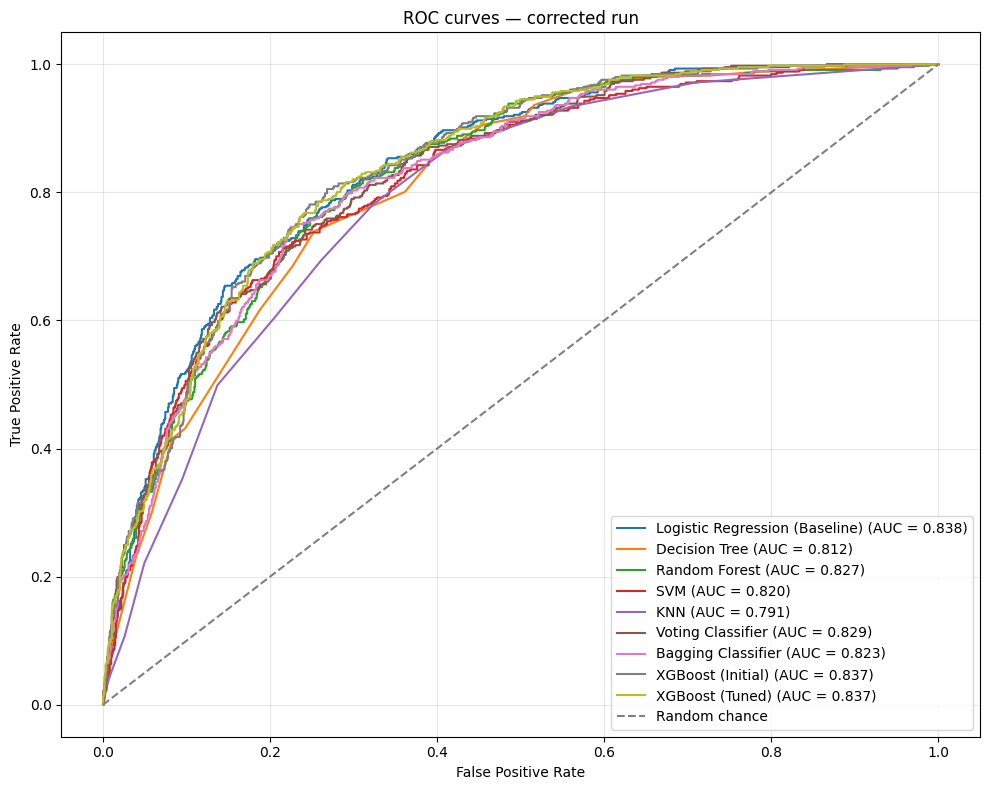

In [29]:
plt.figure(figsize=(10, 8))
for name, proba in probas.items():
    if name in ("Logistic Regression (PCA)", "Logistic Regression (Feature Selection)"):
        continue
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves — corrected run"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/roc_curves.png", dpi=120); plt.show()

## 8.3 Is the LR vs XGBoost difference meaningful? Bootstrap 95% CI of the AUC difference


In [32]:
rng = np.random.RandomState(RANDOM_STATE)
yt = y_test.values
p_lr, p_xgb = probas["Logistic Regression (Baseline)"], probas["XGBoost (Tuned)"]
diffs, aucs_lr = [], []
for _ in range(2000):
    i = rng.randint(0, len(yt), len(yt))
    aucs_lr.append(roc_auc_score(yt[i], p_lr[i]))
    diffs.append(roc_auc_score(yt[i], p_lr[i]) - roc_auc_score(yt[i], p_xgb[i]))
print("LR AUC 95% CI:", np.percentile(aucs_lr, [2.5, 97.5]).round(4))
print("LR − XGBoost AUC difference 95% CI:", np.percentile(diffs, [2.5, 97.5]).round(4))

LR AUC 95% CI: [0.8179 0.8584]
LR − XGBoost AUC difference 95% CI: [-0.0064  0.0092]


**Interpretation:** The 95% confidence interval of the AUC difference between Logistic Regression and XGBoost (−0.006 to +0.009) includes zero, so the two models perform equivalently on this data. The Kaggle difference (0.85625 vs 0.85634) is also within this range.

## 9. Feature importance
Random Forest with the same settings as the original feature-importance cell.

monthly_charges      0.225
total_charges        0.193
contract             0.162
tenure               0.131
payment_method       0.045
online_security      0.036
gender               0.024
paperless_billing    0.023
tech_support         0.020
multiple_lines       0.019
partner              0.019
senior_citizen       0.018
online_backup        0.018
dependents           0.017
device_protection    0.016
streaming_movies     0.012
streaming_tv         0.011
internet_service     0.008
phone_service        0.003


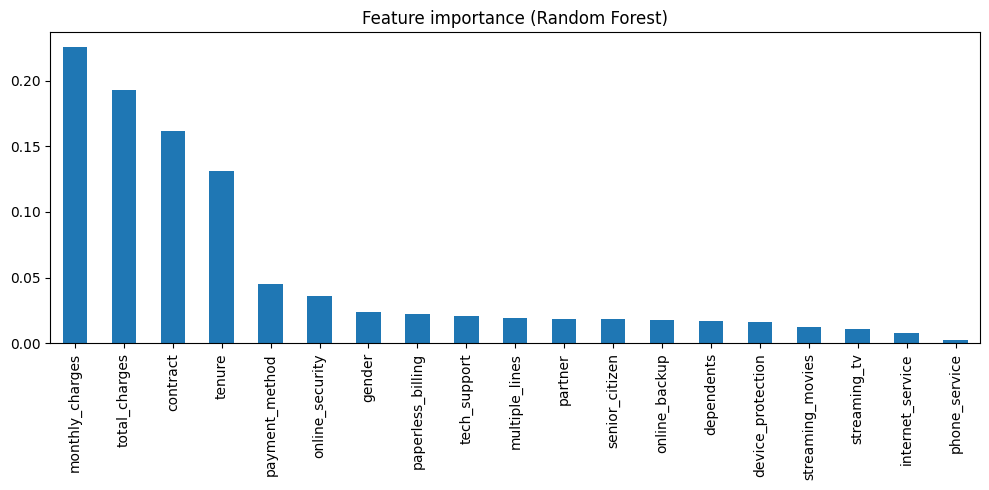

In [30]:
rf_imp = RandomForestClassifier(max_features=40, n_estimators=200, criterion="gini", n_jobs=-1, random_state=RANDOM_STATE)
rf_imp.fit(X_train, y_train)
importances = pd.Series(rf_imp.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances.round(3).to_string())

importances.plot(kind="bar", figsize=(10, 5), title="Feature importance (Random Forest)")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/feature_importance.png", dpi=120); plt.show()

**Interpretation:** Monthly charges, total charges, contract type and tenure account for about 70% of the model’s importance. This matches the EDA: short-tenure, month-to-month customers with high monthly charges churn the most. The original notebook reported payment method and streaming movies as top features; the corrected run does not support that.

## 10. Churn rate by key features
Used for the business recommendations in the README.

In [31]:
for col in ["contract", "payment_method", "internet_service", "online_security", "tech_support"]:
    print(data_raw_input.groupby(col)["label"].agg(["mean", "count"]).round(3), "\n")

tenure_bins = pd.cut(data_raw_input["tenure"], bins=[0, 6, 12, 24, 48, 72], include_lowest=True)
print(data_raw_input.groupby(tenure_bins)["label"].agg(["mean", "count"]).round(3))

                 mean  count
contract                    
Month-to-month  0.432   3104
One year        0.121   1186
Two year        0.028   1344 

                            mean  count
payment_method                         
Bank transfer (automatic)  0.168   1219
Credit card (automatic)    0.164   1217
Electronic check           0.456   1893
Mailed check               0.194   1305 

                   mean  count
internet_service              
DSL               0.192   1934
Fiber optic       0.425   2479
No                0.078   1221 

                      mean  count
online_security                  
No                   0.421   2801
No internet service  0.078   1221
Yes                  0.153   1612 

                      mean  count
tech_support                     
No                   0.419   2781
No internet service  0.078   1221
Yes                  0.160   1632 

                mean  count
tenure                     
(-0.001, 6.0]  0.531   1203
(6.0, 12.0]    0.357    55

## 11. Limitations
- **Categorical encoding:** LabelEncoder assigns integer values to categorical variables, implicitly introducing an ordinal relationship between categories. This may affect models such as Logistic Regression, SVM, and KNN, which can interpret these values as ordered or numeric distances.
- **Preprocessing before cross-validation:** Imputation, encoding, scaling, PCA, and feature selection were fitted on the full training set before cross-validation. As a result, cross-validation scores may be somewhat optimistic. The held-out test set remained separate and was not used to fit these transformations.

## 12. Export outputs (Google Colab only).

In [34]:
import sklearn, xgboost, seaborn, matplotlib
with open("requirements.txt", "w") as f:
    for m in (pd, np, sklearn, xgboost, matplotlib, seaborn):
        name = "scikit-learn" if m.__name__ == "sklearn" else m.__name__
        f.write(f"{name}=={m.__version__}\n")
!zip -r churn_outputs.zip images results requirements.txt
from google.colab import files
files.download("churn_outputs.zip")

updating: images/ (stored 0%)
updating: images/churn_rate_by_category.png (deflated 26%)
updating: images/roc_curves.png (deflated 7%)
updating: images/churn_distribution.png (deflated 19%)
updating: images/numeric_features_by_churn.png (deflated 11%)
updating: images/feature_importance.png (deflated 16%)
updating: results/ (stored 0%)
updating: results/original_vs_corrected.csv (deflated 46%)
updating: results/model_evaluation.csv (deflated 43%)
updating: requirements.txt (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>